# 01: Explore the bill data

**Goal:** load the bills, the house details and the Lahore weather, join them, and look at how electricity use changes with temperature.

Steps:
1. Load the three files
2. Add up all meters of the same house for each month
3. Find the weather for each bill month
4. Keep only clean houses (no solar, all meters known, no empty months)
5. Draw graphs
6. Save the clean table for the model notebook

## 1. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

bills = pd.read_csv("../data/bills.csv")
houses = pd.read_csv("../data/houses.csv")
weather = pd.read_csv("../data/weather_lahore_daily.csv", parse_dates=["date"], index_col="date")

print("Bill rows:", len(bills), "| Meters:", bills["meter_id"].nunique(), "| Houses:", bills["site_id"].nunique())
print("Weather days:", len(weather), "from", weather.index.min().date(), "to", weather.index.max().date())
bills.head()

Bill rows: 104 | Meters: 8 | Houses: 7
Weather days: 822 from 2024-08-01 to 2026-10-31


,building_id,site_id,meter_id,country,city,customer_type,month,year,units,sanctioned_load_kw,tariff,bill_status
0,B01,H001,H001-M1,PK,Lahore,residential,5,2025,217,1,A-1a(01),NaN
1,B01,H001,H001-M1,PK,Lahore,residential,6,2025,507,1,A-1a(01),NaN
2,B01,H001,H001-M1,PK,Lahore,residential,7,2025,351,1,A-1a(01),NaN
3,B01,H001,H001-M1,PK,Lahore,residential,8,2025,340,1,A-1a(01),EX
4,B01,H001,H001-M1,PK,Lahore,residential,9,2025,489,1,A-1a(01),NaN


## 2. Add up the meters of each house

Some houses have two meters (for example one per floor). The bill shows each meter separately, so we add them together for the same month.

In [2]:
monthly = (bills
           .groupby(["site_id", "year", "month"], as_index=False)
           .agg(units=("units", "sum"),
                meters_in_month=("meter_id", "nunique"),
                sanctioned_load_kw=("sanctioned_load_kw", "sum")))
monthly.head()

,site_id,year,month,units,meters_in_month,sanctioned_load_kw
0,H001,2025,5,217,1,1
1,H001,2025,6,507,1,1
2,H001,2025,7,351,1,1
3,H001,2025,8,340,1,1
4,H001,2025,9,489,1,1


## 3. Weather for each bill month

A bill month is **not** a calendar month. LESCO reads the meter around the 20th, so the "October" bill mostly covers 21 September to 20 October.

So for each bill we take the average weather of the 30 days before the 20th of that month.

In [3]:
def weather_for_bill(year, month):
    end = pd.Timestamp(year=year, month=month, day=20)
    start = end - pd.DateOffset(months=1) + pd.DateOffset(days=1)
    w = weather.loc[start:end]
    return pd.Series({
        "avg_temp": round(w["temp_avg_c"].mean(), 1),   # average temperature (C)
        "max_temp": round(w["temp_max_c"].mean(), 1),   # average daily high (C)
        "sun": round(w["sun_kwh_m2_day"].mean(), 2),    # sunlight (kWh per m2 per day)
    })

monthly[["avg_temp", "max_temp", "sun"]] = monthly.apply(
    lambda r: weather_for_bill(int(r["year"]), int(r["month"])), axis=1)

# Season labels for Lahore (by bill month)
season_of = {4: "summer", 5: "summer", 6: "summer", 7: "summer", 8: "summer", 9: "summer",
             11: "winter", 12: "winter", 1: "winter", 2: "winter",
             3: "mild", 10: "mild"}
monthly["season"] = monthly["month"].map(season_of)
monthly.head()

,site_id,year,month,units,meters_in_month,sanctioned_load_kw,avg_temp,max_temp,sun,season
0,H001,2025,5,217,1,1,33.2,41.1,6.34,summer
1,H001,2025,6,507,1,1,37.3,43.9,6.40,summer
2,H001,2025,7,351,1,1,32.1,36.1,4.24,summer
3,H001,2025,8,340,1,1,29.8,33.5,4.72,summer
4,H001,2025,9,489,1,1,28.3,32.1,4.52,summer


## 4. Keep only clean houses

Rules from the project:
- **No solar.** A solar house's bill shows only what it took from the grid, not its real use.
- **All meters known.** If a house has 2 meters but we have 1 bill, the total is too low.
- **No empty months.** Months under 10 units mean the house or meter was not in use.

In [4]:
data = monthly.merge(houses, on="site_id", how="left")

data["reason_out"] = ""
data.loc[data["has_solar"] == 1, "reason_out"] = "has solar"
data.loc[(data["reason_out"] == "") & (data["meters_with_bills"] < data["meters_total"]), "reason_out"] = "missing meter bill"
data.loc[(data["reason_out"] == "") & (data["units"] < 10), "reason_out"] = "near-zero month"

print("Why rows were left out:")
print(data["reason_out"].replace("", "kept").value_counts(), "\n")

clean = data[data["reason_out"] == ""].copy()
print("Clean houses:", sorted(clean["site_id"].unique()))
print("Clean rows:", len(clean))

Why rows were left out:
reason_out
kept                  52
has solar             26
missing meter bill    13
Name: count, dtype: int64 

Clean houses: ['H004', 'H005', 'H006', 'H007']
Clean rows: 52


## 5. Look at the clean data

In [5]:
summary = (clean.groupby("site_id")
           .agg(size_marla=("house_size_marla", "first"),
                people=("people", "first"),
                ac=("ac_total", "first"),
                months=("units", "count"),
                avg_units=("units", "mean"),
                min_units=("units", "min"),
                max_units=("units", "max"))
           .round(0))
summary

,size_marla,people,ac,months,avg_units,min_units,max_units
site_id,,,,,,,
H004,44,9,13,13,1100.0,446,1687
H005,4,6,1,13,248.0,89,923
H006,4,2,1,13,171.0,24,425
H007,7,4,1,13,211.0,78,372


### Units every month, for each house

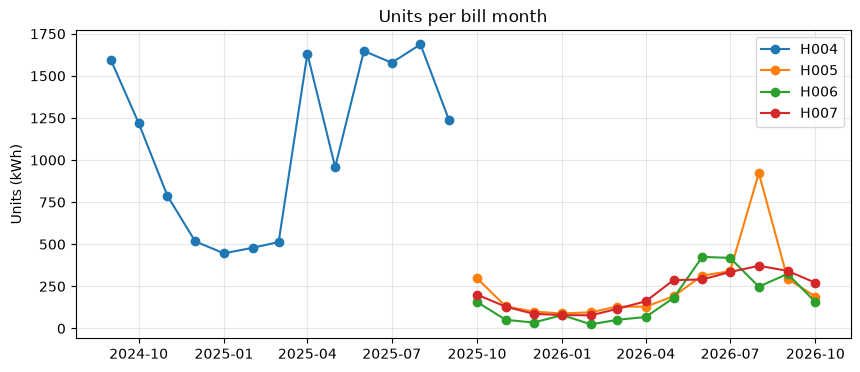

In [6]:
clean["bill_date"] = pd.to_datetime(dict(year=clean["year"], month=clean["month"], day=1))

fig, ax = plt.subplots(figsize=(10, 4))
for site, g in clean.groupby("site_id"):
    g = g.sort_values("bill_date")
    ax.plot(g["bill_date"], g["units"], marker="o", label=site)
ax.set_title("Units per bill month")
ax.set_ylabel("Units (kWh)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Temperature vs units

Each house gets its own small chart, because H004 is a very big house (around 1,600 units in summer) and would squash the others on one chart.

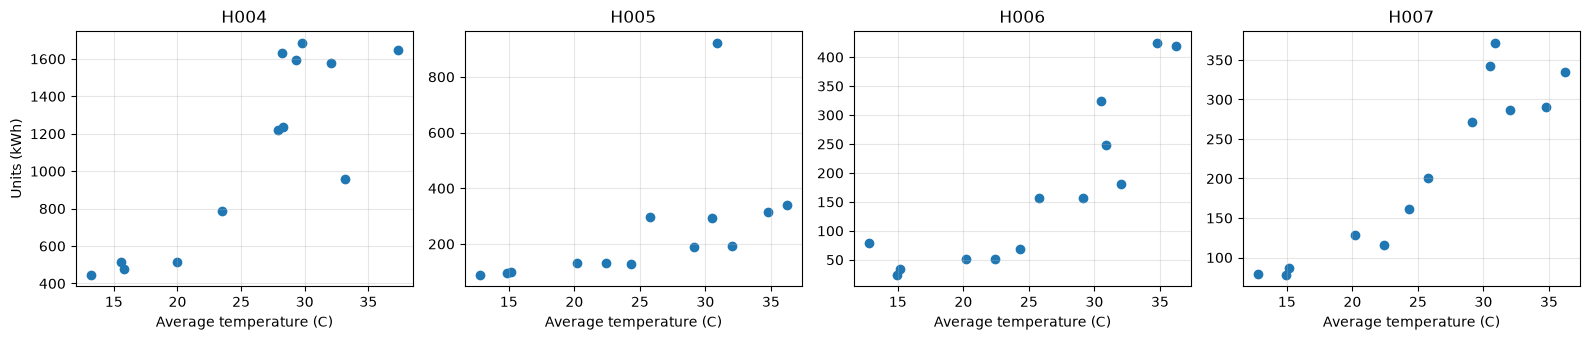

Correlation between temperature and units, per house:
site_id
H004    0.86
H005    0.54
H006    0.86
H007    0.93
Name: (avg_temp, units), dtype: float64


In [7]:
sites = sorted(clean["site_id"].unique())
fig, axes = plt.subplots(1, len(sites), figsize=(4 * len(sites), 3.5))
for ax, site in zip(axes, sites):
    g = clean[clean["site_id"] == site]
    ax.scatter(g["avg_temp"], g["units"])
    ax.set_title(site)
    ax.set_xlabel("Average temperature (C)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Units (kWh)")
plt.tight_layout()
plt.show()

print("Correlation between temperature and units, per house:")
print(clean.groupby("site_id")[["avg_temp", "units"]].corr().unstack().iloc[:, 1].round(2))

### Summer vs winter

How many times more electricity a house uses in summer than in winter.

In [8]:
season_avg = clean.pivot_table(index="site_id", columns="season", values="units", aggfunc="mean").round(0)
season_avg["summer_vs_winter"] = (season_avg["summer"] / season_avg["winter"]).round(1)
season_avg[["winter", "mild", "summer", "summer_vs_winter"]]

season,winter,mild,summer,summer_vs_winter
site_id,,,,
H004,558.0,866.0,1476.0,2.6
H005,104.0,206.0,365.0,3.5
H006,47.0,122.0,278.0,5.9
H007,93.0,196.0,298.0,3.2


### The unusual month in H005

H005 (Asad bhai's lower portion) used 923 units in the August 2026 bill, about 3 times July and September. The owner says the AC ran much more that month. It is real data, so we keep it, but we mark it so the model notebook can test with and without it.

In [9]:
clean["is_outlier"] = (clean["site_id"] == "H005") & (clean["year"] == 2026) & (clean["month"] == 8)
clean[clean["site_id"] == "H005"][["year", "month", "units", "avg_temp", "is_outlier"]].sort_values(["year", "month"])

,year,month,units,avg_temp,is_outlier
52,2025,10,298,25.8,False
53,2025,11,131,20.2,False
54,2025,12,100,15.2,False
55,2026,1,89,12.8,False
56,2026,2,96,14.9,False
57,2026,3,130,22.4,False
58,2026,4,129,24.3,False
59,2026,5,191,32.0,False
60,2026,6,314,34.8,False
61,2026,7,340,36.2,False


## 6. Save the clean table

In [10]:
cols = ["site_id", "building_id", "year", "month", "season", "units", "avg_temp", "max_temp", "sun",
        "sanctioned_load_kw", "house_size_marla", "people", "ac_total", "fans_total",
        "fridge_total", "ups", "is_outlier"]
clean[cols].sort_values(["site_id", "year", "month"]).to_csv("../data/clean_monthly.csv", index=False)
print("Saved", len(clean), "rows to data/clean_monthly.csv")

Saved 52 rows to data/clean_monthly.csv


## Bonus: how much 1 kW of solar really makes in Lahore

H003 has a 10 kW system. Its monthly output (read from the inverter app) divided by 10 gives the output of 1 kW, which the solar calculator will use.

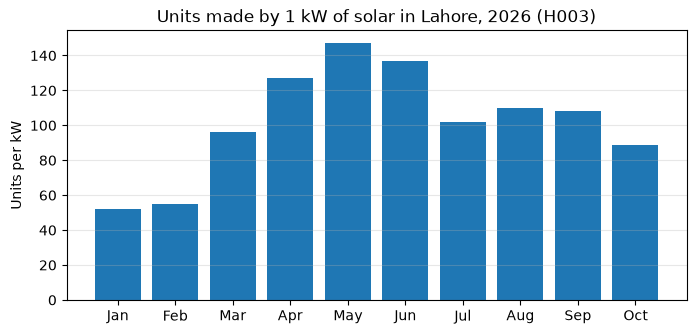

Total Jan to Oct: 1023 units per kW
Correlation with NASA sunlight: 0.94


,month,kwh_per_kw,sun
0,1,52.0,2.48
1,2,55.0,4.26
2,3,96.0,4.74
3,4,127.0,5.95
4,5,147.0,6.56
5,6,137.0,6.55
6,7,102.0,4.85
7,8,110.0,5.22
8,9,108.0,5.32
9,10,89.0,4.37


In [11]:
solar = pd.read_csv("../data/solar_monthly.csv")
solar["kwh_per_kw"] = (solar["kwh"] / solar["system_kw"]).round(0)
cal_sun = weather["sun_kwh_m2_day"].resample("MS").mean()
solar["sun"] = [round(cal_sun[pd.Timestamp(year=y, month=m, day=1)], 2) for y, m in zip(solar["year"], solar["month"])]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(solar["month"], solar["kwh_per_kw"])
ax.set_xticks(solar["month"])
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"])
ax.set_title("Units made by 1 kW of solar in Lahore, 2026 (H003)")
ax.set_ylabel("Units per kW")
ax.grid(axis="y", alpha=0.3)
plt.show()

print("Total Jan to Oct:", int(solar["kwh_per_kw"].sum()), "units per kW")
print("Correlation with NASA sunlight:", round(solar["kwh_per_kw"].corr(solar["sun"]), 2))
solar[["month", "kwh_per_kw", "sun"]]